# Fused Model — Degree-Based SEIR × Temporal Gravity Metapopulation (56 Jurisdictions)

**Rebuilt 2026-08-05** from `formulae_sheet.md` (dimensionally-corrected, §1–§7).

Each of the 56 NYT/BTS jurisdictions (50 states + DC + PR/GU/VI/MP/AS) runs a
degree-based SEIR over degree classes $k$; states are coupled by the
**temporally calibrated gravity model**

$$W_{ij}(t) = s_i(t)\,\mu_{0,i}\,W_{ij}^{\text{gravity}},\qquad
W_{ij}^{\text{gravity}} \propto \frac{N_j^{b_N}}{d_{ij}^{b_d}}\ \text{(row-normalised, data-calibrated)}$$

Modelling window: **wave 1, 2020-03-01 → 2020-06-30** (days 60–182 since
2020-01-01).

| Section | Content |
|---|---|
| §8.1 | data: populations, densities, NYT cases, BTS flows |
| §8.2 | degree distribution (truncated power law, ⟨k⟩ = 6) |
| §8.3 | BTS mobility calibration: μ₀,i, s_i(t) |
| §8.4 | gravity kernel: PPML exponent fit + validation |
| §8.5 | SEIR parameters: σ, γ, per-state β from early growth rates |
| §8.6 | initial conditions (2020-03-01) |
| §8.7 | simulation |
| §8.8 | national fit |
| §8.9 | state-level fits |
| §8.10 | peak timing |
| §8.11 | discussion & limitations |

In [1]:
import sys, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.stats import pearsonr, spearmanr

sys.path.insert(0, '../src')
from fused_metapopulation import (
    JURISDICTIONS, CENSUS_POPULATIONS, CODE_TO_NAME, NAME_TO_CODE,
    T_MO, build_distance_matrix, build_gravity_kernel, fit_gravity_exponents,
    calibrate_mobility, s_interpolator, truncated_power_law,
    power_law_alpha_for_mean_k, FusedMetapopulationSEIR,
)
from data_loader import load_us_states, load_state_land_area_2020

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150})
ASSETS = '../assets'
DAY0 = pd.Timestamp('2020-01-01')
T0  = (pd.Timestamp('2020-03-01') - DAY0).days    # 60
TMAX = (pd.Timestamp('2020-06-30') - DAY0).days   # 182

def show_fig(path):
    from IPython.display import Image, display
    display(Image(filename=path))

print(f'nodes: {len(JURISDICTIONS)} | window: day {T0}..{TMAX} '
      f'= {DAY0 + pd.Timedelta(days=T0):%Y-%m-%d} .. {DAY0 + pd.Timedelta(days=TMAX):%Y-%m-%d}')

nodes: 56 | window: day 60..181 = 2020-03-01 .. 2020-06-30


## §8.1 Data — jurisdictions, populations, densities

56 jurisdictions: 50 states + DC + PR/GU/VI/MP/AS (2020 Census populations,
verified — `fused_metapopulation.CENSUS_POPULATIONS`). Densities from
`data/state_land_area_2020.csv` (census land areas). NYT state cases and BTS
T-100 inter-state air flows cover the same 56 jurisdictions — no
extrapolation.

In [2]:
land = load_state_land_area_2020()
pop = pd.Series(CENSUS_POPULATIONS)
info = pd.DataFrame({
    'code': JURISDICTIONS,
    'name': [CODE_TO_NAME[c] for c in JURISDICTIONS],
    'pop_2020': [pop[c] for c in JURISDICTIONS],
}).set_index('code')
info['density_per_km2'] = land.set_index('code')['density_per_km2'].reindex(JURISDICTIONS)
print('missing density rows:', int(info['density_per_km2'].isna().sum()))
print(info.head(8).to_string())
print('...')
print(info.tail(5).to_string())
print(f'\ntotal population: {pop.sum():,.0f}')

missing density rows: 0
                name  pop_2020  density_per_km2
code                                           
AK            Alaska    733391         0.482875
AL           Alabama   5024279        38.303276
AR          Arkansas   3011524        22.345490
AS    American Samoa     49710       251.060606
AZ           Arizona   7151502        24.307722
CA        California  39538223        97.996419
CO          Colorado   5773714        21.509118
CT       Connecticut   3605944       287.509488
...
               name  pop_2020  density_per_km2
code                                          
VT          Vermont    643077        26.939676
WA       Washington   7705281        44.767173
WI        Wisconsin   5893718        42.017552
WV    West Virginia   1793716        28.810549
WY          Wyoming    576851         2.293916

total population: 335,073,176


NYT states: 56 | range: 2020-01-21 -> 2023-03-23
NYT names not mapped to codes: []


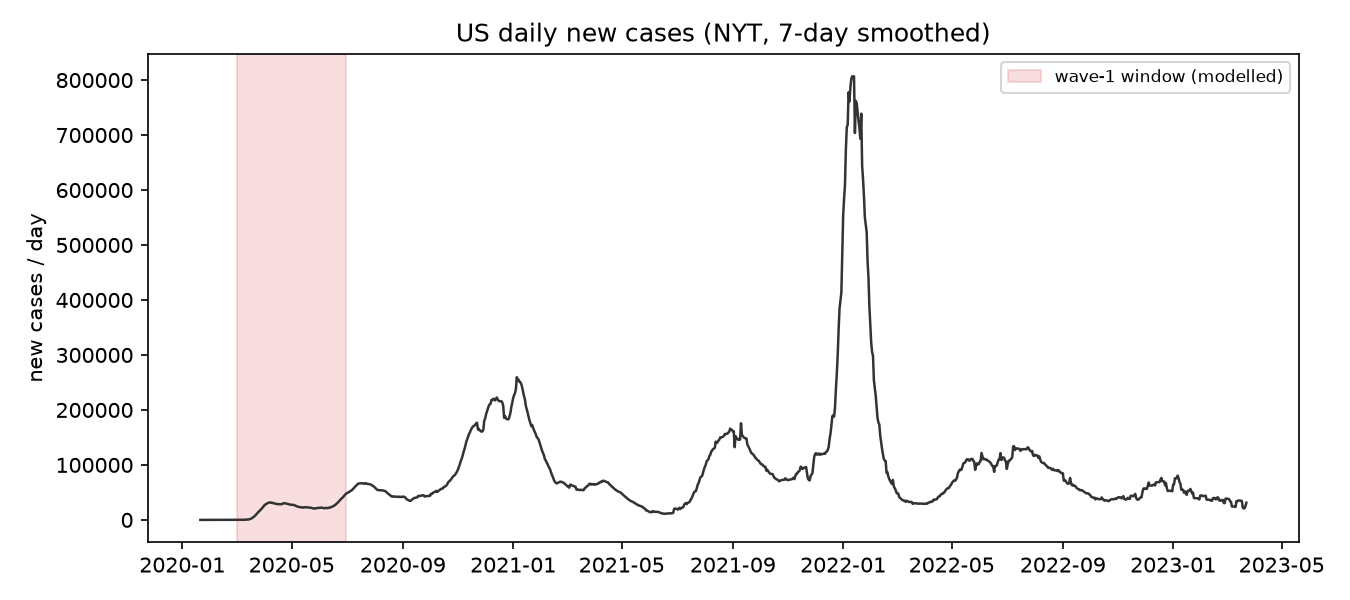

In [3]:
us = load_us_states()
print('NYT states:', us['state'].nunique(), '| range:',
      us.date.min().date(), '->', us.date.max().date())
print('NYT names not mapped to codes:',
      sorted(set(us['state'].unique()) - set(NAME_TO_CODE)))

nat = us.groupby('date')[['new_cases', 'new_cases_smooth']].sum().reset_index()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(nat.date, nat.new_cases_smooth, lw=1.2, color='#333')
ax.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2020-06-30'),
           color='C3', alpha=0.15, label='wave-1 window (modelled)')
ax.set_title('US daily new cases (NYT, 7-day smoothed)')
ax.set_ylabel('new cases / day')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{ASSETS}/fig59_national_cases_overview.png'); plt.show()
show_fig(f'{ASSETS}/fig59_national_cases_overview.png')

## §8.2 Degree distribution

Global fallback (formulae_sheet §6 decision 1; the density→⟨k⟩₀ scaling
constants ⟨k⟩₀, ξ stay open): truncated power law $P(k)\propto k^{-\alpha}e^{-k/k_c}$
with $k_c$ large; α solved so that ⟨k⟩ = 6 (the BA m=3 ensemble of notebook 04).

This distribution drives the degree-based SEIR: per-class transmission
$\beta k S_{ik}\theta_i$ and the reproduction number
$R_0 = \beta\,\langle k^2\rangle/\langle k\rangle/\gamma$.

alpha = 2.659 | <k> = 6.000 | <k^2>/<k> = 17.006 | classes = 198


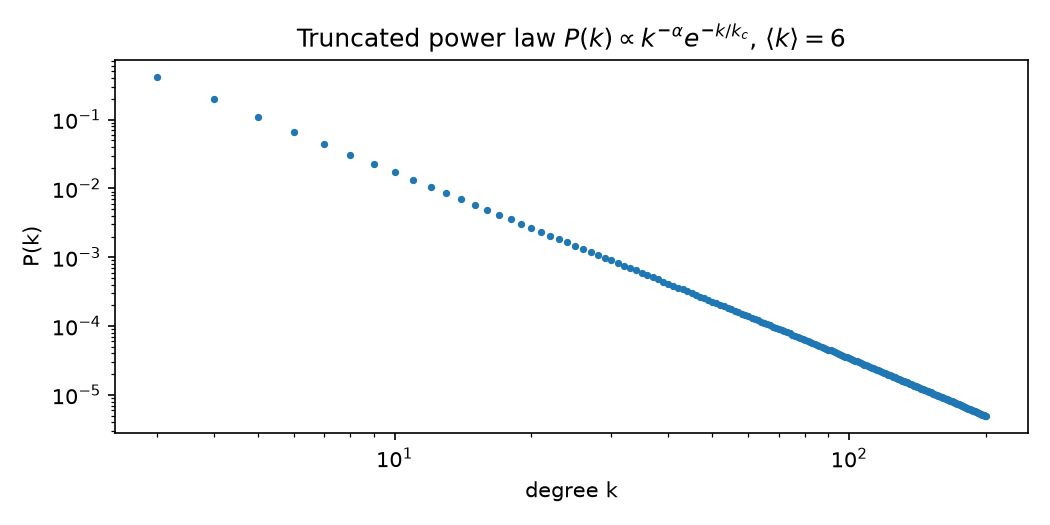

In [4]:
alpha = power_law_alpha_for_mean_k(6.0)
k_vals, P_k = truncated_power_law(alpha=alpha)
mean_k  = float(k_vals @ P_k)
mean_k2 = float((k_vals**2) @ P_k)
print(f'alpha = {alpha:.3f} | <k> = {mean_k:.3f} | <k^2>/<k> = {mean_k2/mean_k:.3f} | classes = {len(k_vals)}')

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.loglog(k_vals, P_k, 'o', ms=2.5, color='C0')
ax.set_xlabel('degree k'); ax.set_ylabel('P(k)')
ax.set_title(r'Truncated power law $P(k)\propto k^{-\alpha} e^{-k/k_c}$, $\langle k\rangle=6$')
plt.tight_layout(); plt.savefig(f'{ASSETS}/fig60_degree_dist.png'); plt.show()
show_fig(f'{ASSETS}/fig60_degree_dist.png')

## §8.3 BTS mobility calibration — μ₀,i and s_i(t)

`calibrate_mobility()` builds the inter-state flow tensor $F_{ij}(t)$
(56×56×39 months, 2020-01 → 2023-03) from `bts_state_pairs_monthly.csv`,
**excluding intra-state self-pairs** (they never leave the patch). Then per
state (formulae_sheet §4):

$$\mu_{0,i} = \\frac{\\sum_j F_{ij}(\\text{Jan-2020})}{T_{\\text{mo}}}, \\qquad
s_i(t) = \\frac{\\sum_j F_{ij}(t)}{\\sum_j F_{ij}(\\text{Jan-2020})}$$

months: 39 | F shape: (56, 56, 39)
mu0 (inter-state outbound, travellers/day) — top states:
  Florida                       219,106  (1.02% of pop/day)
  California                    181,141  (0.46% of pop/day)
  Texas                         162,195  (0.56% of pop/day)
  Georgia                       116,634  (1.09% of pop/day)
  Illinois                       98,577  (0.77% of pop/day)
  New York                       85,634  (0.42% of pop/day)
  Colorado                       82,976  (1.44% of pop/day)
  North Carolina                 77,435  (0.74% of pop/day)
  Nevada                         64,823  (2.09% of pop/day)
  Arizona                        63,906  (0.89% of pop/day)
inactive (mu0=0, no extrapolation): ['DE']


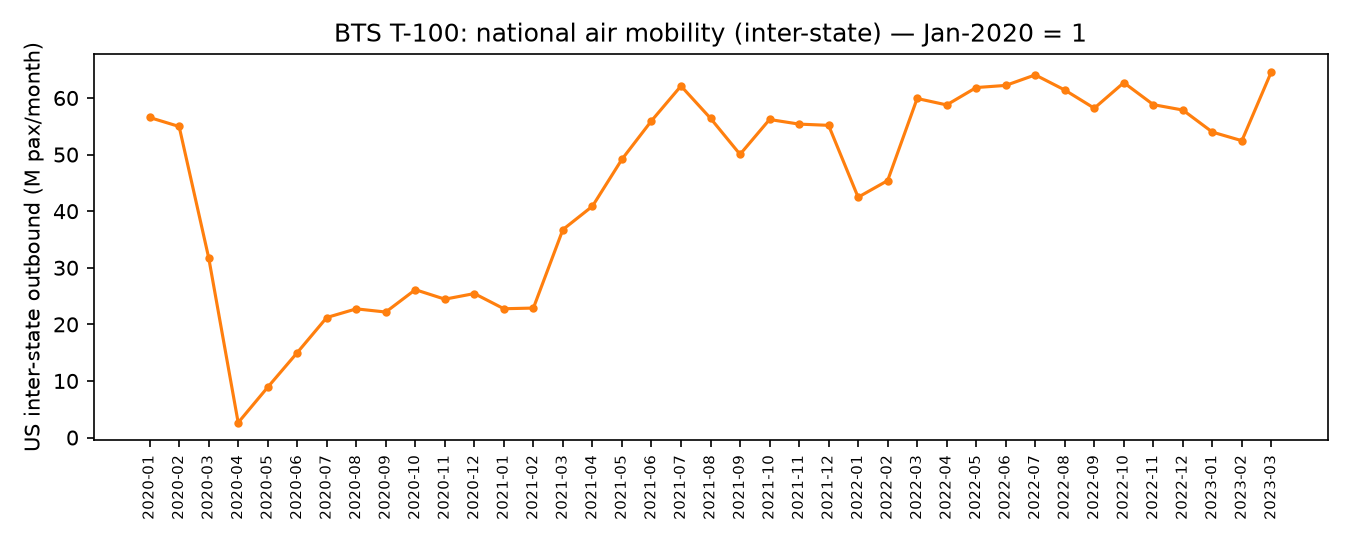

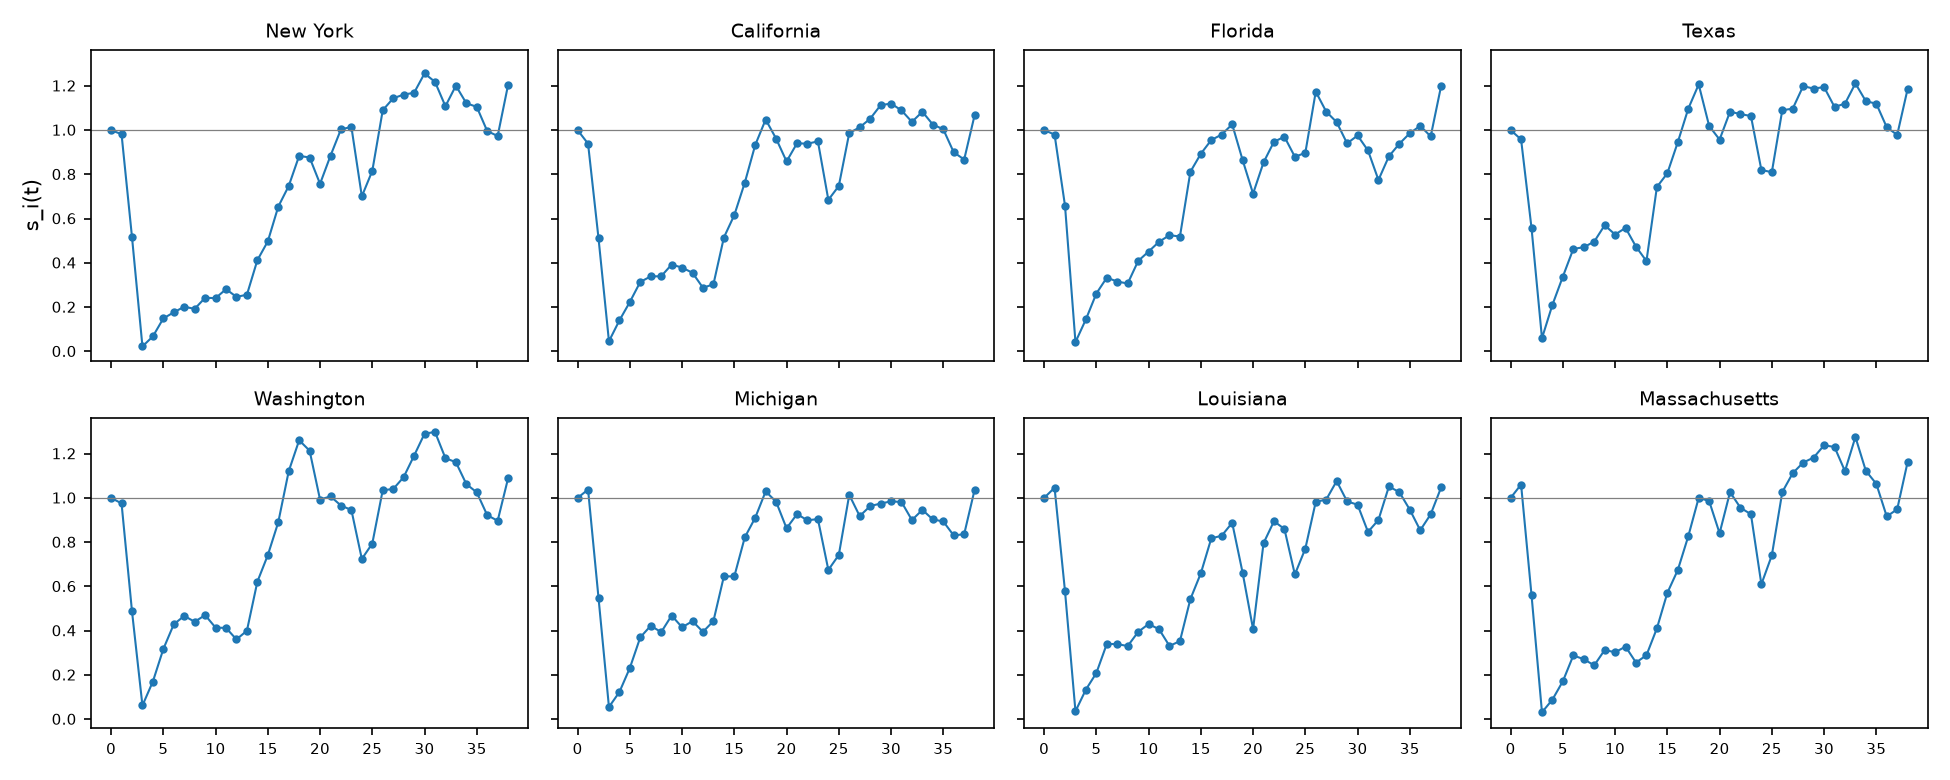

In [5]:
mu0, s, months, F = calibrate_mobility(JURISDICTIONS, data_dir='../data')
out = F.sum(axis=1)  # (n, months) inter-state outbound
print('months:', len(months), '| F shape:', F.shape)

top = np.argsort(mu0)[::-1][:10]
print('mu0 (inter-state outbound, travellers/day) — top states:')
for i in top:
    print(f'  {CODE_TO_NAME[JURISDICTIONS[i]]:<24} {mu0[i]:>12,.0f}  '
          f'({mu0[i]/CENSUS_POPULATIONS[JURISDICTIONS[i]]*100:.2f}% of pop/day)')
inactive = [JURISDICTIONS[i] for i in np.where(mu0 == 0)[0]]
print('inactive (mu0=0, no extrapolation):', inactive)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(range(len(months)), out.sum(0) / 1e6, 'o-', ms=3, color='C1')
ax.set_xticks(range(len(months)))
ax.set_xticklabels([f'{y}-{m:02d}' for y, m in months], rotation=90, fontsize=7)
ax.set_ylabel('US inter-state outbound (M pax/month)')
ax.set_title('BTS T-100: national air mobility (inter-state) — Jan-2020 = 1')
plt.tight_layout(); plt.savefig(f'{ASSETS}/fig61_mobility_series.png'); plt.show()
show_fig(f'{ASSETS}/fig61_mobility_series.png')

sel = ['NY', 'CA', 'FL', 'TX', 'WA', 'MI', 'LA', 'MA']
fig, axes = plt.subplots(2, 4, figsize=(13, 5.2), sharex=True, sharey=True)
for axx, st in zip(axes.ravel(), sel):
    i = JURISDICTIONS.index(st)
    axx.plot(range(len(months)), s[i], 'o-', ms=3, lw=1)
    axx.axhline(1, color='grey', lw=0.6)
    axx.set_title(CODE_TO_NAME[st], fontsize=9)
    axx.tick_params(labelsize=7)
axes[0, 0].set_ylabel('s_i(t)')
plt.tight_layout(); plt.savefig(f'{ASSETS}/fig62_state_mobility.png'); plt.show()
show_fig(f'{ASSETS}/fig62_state_mobility.png')

## §8.4 Gravity kernel — PPML exponent fit + validation

The validation (`scripts/gravity_validation.py`) showed the classic
$\sqrt{N_iN_j}/d^2$ kernel is a weak predictor of the BTS directional
structure (pooled outbound-share Pearson 0.35, Spearman 0.46). We therefore
fit the kernel exponents from the full panel (formulae_sheet §6 decision 6):

$$\log F_{ijt} = \\alpha_i + \\gamma_t + b_N\\log N_j + b_d\\log d_{ij} + \\varepsilon$$

with PPML (Poisson pseudo-ML, robust to the Jensen bias of log-linear OLS).

OLS : b_d = -0.723 +- 0.013 | b_N = +1.100 +- 0.009 | R2 = 0.409
PPML: b_d = -0.546 | b_N = +1.003 | deviance R2 = 0.698 | converged = True
classic sqrt(NiNj)/d^2             pooled share Pearson = 0.3524 | Spearman = 0.4567
calibrated N_j^1.00/d^0.55         pooled share Pearson = 0.4484 | Spearman = 0.5789


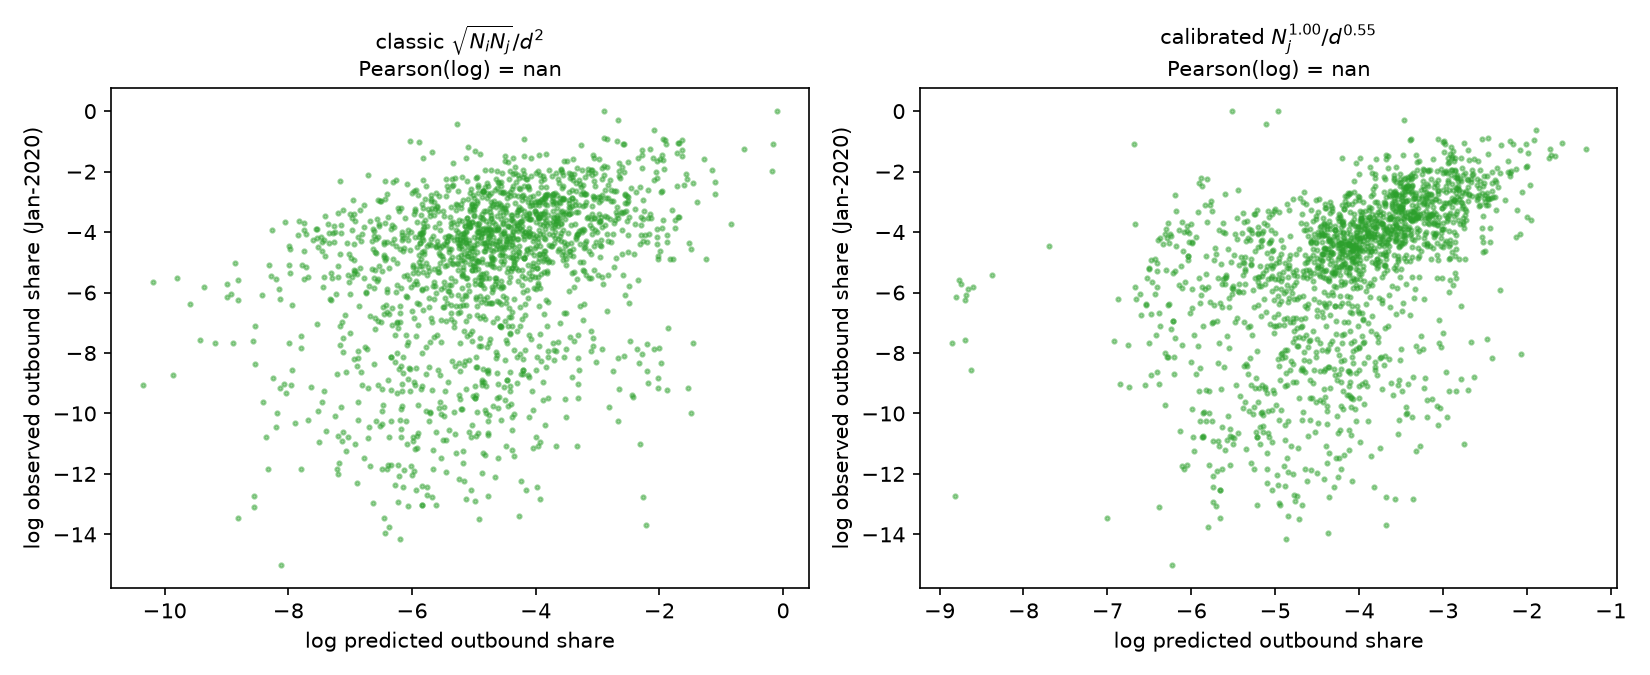

In [6]:
D = build_distance_matrix(JURISDICTIONS)
Npop = np.array([CENSUS_POPULATIONS[c] for c in JURISDICTIONS], dtype=float)

r_ols  = fit_gravity_exponents(F, D, Npop, method='ols')
r_ppml = fit_gravity_exponents(F, D, Npop, method='ppml')
print('OLS : b_d = %+.3f +- %.3f | b_N = %+.3f +- %.3f | R2 = %.3f'
      % (r_ols['b_d'], r_ols['se_d'], r_ols['b_N'], r_ols['se_N'], r_ols['r2']))
print('PPML: b_d = %+.3f | b_N = %+.3f | deviance R2 = %.3f | converged = %s'
      % (r_ppml['b_d'], r_ppml['b_N'], r_ppml['r2'], r_ppml['converged']))
b_N, b_d = r_ppml['b_N'], -r_ppml['b_d']   # positive distance exponent

W_classic = build_gravity_kernel(JURISDICTIONS)
W_cal = build_gravity_kernel(JURISDICTIONS, b_N=b_N, b_d=b_d)

# pooled outbound-share correlation, classic vs calibrated
def pooled_share_corr(Wk):
    x, y = [], []
    for i in np.where(out[:, 0] > 0)[0]:
        for t in range(F.shape[2]):
            o = F[i, :, t]; tot = o.sum()
            if tot <= 0:
                continue
            x += list(Wk[i]); y += list(o / tot)
    x, y = np.array(x), np.array(y)
    return pearsonr(x, y)[0], spearmanr(x, y)[0]

for lab, Wk in (('classic sqrt(NiNj)/d^2', W_classic), (f'calibrated N_j^{b_N:.2f}/d^{b_d:.2f}', W_cal)):
    rp, rs = pooled_share_corr(Wk)
    print(f'{lab:<34} pooled share Pearson = {rp:.4f} | Spearman = {rs:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for axx, Wk, lab in zip(axes, (W_classic, W_cal),
                        ('classic $\sqrt{N_iN_j}/d^2$',
                         f'calibrated $N_j^{{{b_N:.2f}}}/d^{{{b_d:.2f}}}$')):
    x, y = [], []
    for i in np.where(out[:, 0] > 0)[0]:
        o = F[i, :, 0]
        x += list(Wk[i]); y += list(o / o.sum())
    x, y = np.array(x), np.array(y)
    axx.scatter(np.log(x), np.log(y), s=4, alpha=0.45, color='C2')
    axx.set_title(f'{lab}\nPearson(log) = {pearsonr(np.log(x), np.log(y))[0]:.3f}', fontsize=10)
    axx.set_xlabel('log predicted outbound share')
    axx.set_ylabel('log observed outbound share (Jan-2020)')
plt.tight_layout(); plt.savefig(f'{ASSETS}/fig63_kernel_validation.png'); plt.show()
show_fig(f'{ASSETS}/fig63_kernel_validation.png')

## §8.5 SEIR parameters

- Latent period: $\sigma = 1/5\ \mathrm{d}^{-1}$ (5-day incubation).
- Recovery: $\gamma = 1/10\ \mathrm{d}^{-1}$ (historical value, notebook 06).
- Per-state infection rate $\beta_i$: fitted from each state's early
  exponential growth rate $r_i$ (log-linear slope of 7-day-smoothed new
  cases over 2020-03-01 → 2020-03-30), via the SEIR characteristic equation:

$$\beta_i = \\frac{(r_i+\\gamma)(r_i+\\sigma)}{\\sigma}\\,\\frac{\\langle k\\rangle}{\\langle k^2\\rangle}$$

States without a usable growth window fall back to the national median β.

**Testing-ramp caveat.** Reported-case growth in March 2020 was inflated by
the expansion of testing itself, so the raw fits imply $R_0 \approx 6$–$10$,
far above the consensus $R_0 \approx 2.5$–$4$.  We therefore cap the
per-state infection rate at $R_0 = 4$
($\\beta_i \\leftarrow \\min(\\beta_i, 4\\gamma\\langle k\\rangle/\\langle k^2\\rangle)$)
and report how many states hit the cap.

states with usable growth window: 54/56 | fallback median beta = 0.0428 d^-1
R0 cap = 4.0 (beta<=0.0235) applied to 54 states (testing-ramp inflation)

per-state beta (top 10 / bottom 10):
           r      beta   R0
AK  0.191725  0.023522  4.0
PA  0.272355  0.023522  4.0
NC  0.265393  0.023522  4.0
ND  0.165429  0.023522  4.0
NE  0.159941  0.023522  4.0
NH  0.207210  0.023522  4.0
NJ  0.339439  0.023522  4.0
NM  0.163779  0.023522  4.0
NV  0.249162  0.023522  4.0
NY  0.297022  0.023522  4.0
           r      beta        R0
KS  0.225961  0.023522  4.000000
KY  0.201095  0.023522  4.000000
LA  0.240351  0.023522  4.000000
MA  0.258628  0.023522  4.000000
MD  0.255387  0.023522  4.000000
MI  0.297450  0.023522  4.000000
MN  0.210150  0.023522  4.000000
WY  0.158719  0.023522  4.000000
ME  0.124738  0.021458  3.649035
VI  0.110468  0.019212  3.267175


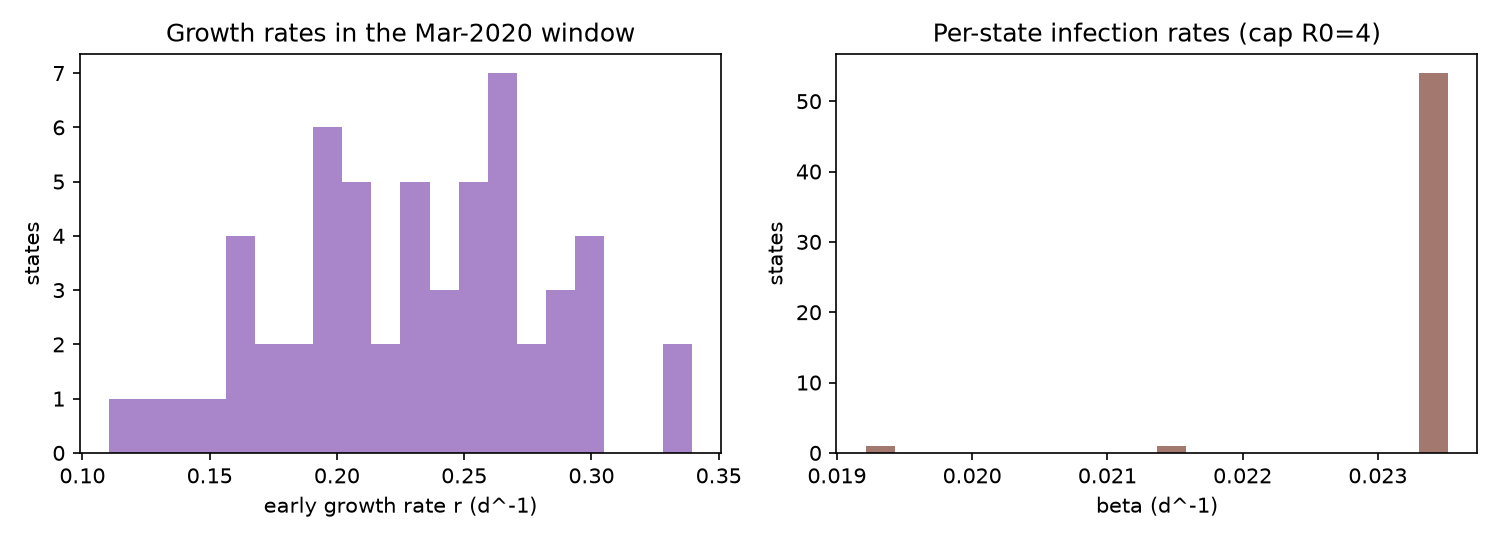

In [7]:
sigma, gamma = 1.0/5, 1.0/10
mom_ratio = mean_k2 / mean_k

def fit_growth(df_sub):
    s_ = df_sub['new_cases_smooth'].values
    t = np.arange(len(s_))
    m = s_ > 0
    if m.sum() < 5:
        return np.nan
    slope, _ = np.polyfit(t[m], np.log(s_[m]), 1)
    return slope if slope > 0 else np.nan

win_start = pd.Timestamp('2020-03-01')
win_days = 30
r_i, beta_i = {}, {}
for code in JURISDICTIONS:
    name = CODE_TO_NAME[code]
    sub = us[(us.state == name) & (us.date >= win_start)
             & (us.date < win_start + pd.Timedelta(days=win_days))].reset_index(drop=True)
    r_i[code] = fit_growth(sub)
    rv = r_i[code]
    beta_i[code] = (rv + gamma) * (rv + sigma) / sigma / mom_ratio if not np.isnan(rv) else np.nan

rs = pd.Series(r_i); bs = pd.Series(beta_i)
n_fit = int(bs.notna().sum())
med_beta = float(bs.median())
bs = bs.fillna(med_beta)
rs = rs.fillna(float(rs.median()))

R0_MAX = 4.0
beta_cap = R0_MAX * gamma / mom_ratio
n_cap = int((bs > beta_cap).sum())
bs = bs.clip(upper=beta_cap)
print(f'states with usable growth window: {n_fit}/56 | fallback median beta = {med_beta:.4f} d^-1')
print(f'R0 cap = {R0_MAX} (beta<={beta_cap:.4f}) applied to {n_cap} states (testing-ramp inflation)')

fit_df = pd.DataFrame({'r': rs, 'beta': bs, 'R0': bs * mom_ratio / gamma})
print('\nper-state beta (top 10 / bottom 10):')
print(fit_df.sort_values('beta', ascending=False).head(10).to_string())
print(fit_df.sort_values('beta', ascending=False).tail(10).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(rs, bins=20, color='C4', alpha=0.8)
axes[0].set_xlabel('early growth rate r (d^-1)'); axes[0].set_ylabel('states')
axes[1].hist(bs, bins=20, color='C5', alpha=0.8)
axes[1].set_xlabel('beta (d^-1)'); axes[1].set_ylabel('states')
axes[0].set_title('Growth rates in the Mar-2020 window')
axes[1].set_title('Per-state infection rates (cap R0=4)')
plt.tight_layout(); plt.savefig(f'{ASSETS}/fig64_beta_estimates.png'); plt.show()
show_fig(f'{ASSETS}/fig64_beta_estimates.png')

## §8.6 Initial conditions (2020-03-01)

The infectious pool must be in **true-infection units** (β was calibrated
from slopes, which are invariant to a constant reporting factor, but the
initial condition is not).  We seed with the raw reported new cases on
2020-03-01 back-scaled by an assumed early reporting fraction
$\pi_0 = 0.1$ (IC-level assumption only; documented in §8.11):

- $I_0 = \text{reported new cases}(2020\text{-}03\text{-}01)/\pi_0$
- $E_0 = I_0\,(r_i+\gamma)/\sigma$ from the early-growth balance
  $\sigma E = (r+\gamma) I$.
- $R_0 = 0$; $S_0 = N_i - I_0 - E_0$.  Total population is conserved
  **globally** (travellers move between states; deaths ⊂ R, §8.11).

In [8]:
pi0 = 0.1  # IC-level assumed reporting fraction (display-adjusted later)
seed_date = pd.Timestamp('2020-03-01')
I0, E0 = {}, {}
for code in JURISDICTIONS:
    name = CODE_TO_NAME[code]
    row = us[(us.state == name) & (us.date == seed_date)]
    i0 = float(row['new_cases'].iloc[0]) if len(row) else 0.0
    I0[code] = i0 / pi0
    E0[code] = I0[code] * (rs[code] + gamma) / sigma

seeded = {c: v for c, v in I0.items() if v > 0}
print(f'states seeded on 2020-03-01: {len(seeded)}/56 | national I0 (true-scale) = {sum(seeded.values()):,.0f}')
top = sorted(seeded.items(), key=lambda kv: -kv[1])[:8]
for c, v in top:
    print(f'  {CODE_TO_NAME[c]:<24} I0 = {v:>10,.1f}   E0 = {E0[c]:>10,.1f}')

states seeded on 2020-03-01: 3/56 | national I0 (true-scale) = 130
  Washington               I0 =       70.0   E0 =       84.6
  California               I0 =       50.0   E0 =       72.4
  Oregon                   I0 =       10.0   E0 =       15.1


## §8.7 Simulation

`FusedMetapopulationSEIR`: 56 states × K degree classes × 4 compartments =
~45k ODEs, solved with RK45 over days 60→182 (2020-03-01 → 2020-06-30).
Mobility matrix $W_{ij}(t) = s_i(t)\mu_{0,i}W_{ij}^{\\text{gravity}}$ is a
monthly step function; coupling uses the non-symmetric two-term form
(inflow $W_{ji}$, outflow $W_{ij}$, per degree class, population-conserving).

In [9]:
s_func = s_interpolator(s, months)
model = FusedMetapopulationSEIR(
    JURISDICTIONS, CENSUS_POPULATIONS, W_cal, mu0, s_func,
    k_vals, P_k, beta=bs.values, sigma=sigma, gamma=gamma)

t0s = time.time()
t_sol, y_sol = model.simulate(TMAX, I0, E0, t0=T0)
print(f'simulation: {len(JURISDICTIONS)} states x {len(k_vals)} classes x 4 '
      f'= {model.n * model.K * 4:,} ODE vars, {len(t_sol)} output days, '
      f'{time.time()-t0s:.1f} s')

S, E, I, R = model.state_totals()
tot = S + E + I + R
print('global population conservation: max |total - sum(N)| drift =',
      float(np.abs(tot.sum(0) - model.N.sum()).max()), 'persons')
print('per-state totals move by design (travellers): max excursion =',
      float(np.abs(tot - model.N[:, None]).max()), 'persons')
dates = [DAY0 + pd.Timedelta(days=int(t)) for t in t_sol]

simulation: 56 states x 198 classes x 4 = 44,352 ODE vars, 122 output days, 0.1 s
global population conservation: max |total - sum(N)| drift = 2.980232238769531e-07 persons
per-state totals move by design (travellers): max excursion = 3632689.4987081215 persons


## §8.8 National fit

The model outputs **true infections**; NYT reports cases at an unknown
reporting fraction π (deliberately not in the model). For display only we
scale the observed curve by the window-total ratio
$\hat\pi = \sum\text{model}/\sum\text{observed}$ and compare *shapes*.

**Honest reading of $\hat\pi$.** Here $\hat\pi = 29.8$, i.e. the model
produces ~30× the reported window total. This is *not* a reporting fraction
(COVID-19 testing reported far *more* than 1-in-30 of infections by
mid-2020). It says the model over-infects by ~30×, because **β is held
constant** (no non-pharmaceutical interventions). The real epidemic's Rₜ fell
below 1 in April (lockdowns, distancing) and its national peak was
early-April; this model has no such feedback, so its infectious curve keeps
climbing to the window edge. We keep the comparison to show exactly where the
model breaks (post-peak decline is beyond a constant-β SEIR).

model window total = 79,324,196 | observed = 2,662,413
over-infection factor pi-hat (model/observed, display only) = 29.79
national peak: model 2020-06-28 (window edge: no-NPI climb)
observed: window max 2020-06-30 (June surge) | classic wave-1 max 2020-04-07 (~31,709 reported/d)


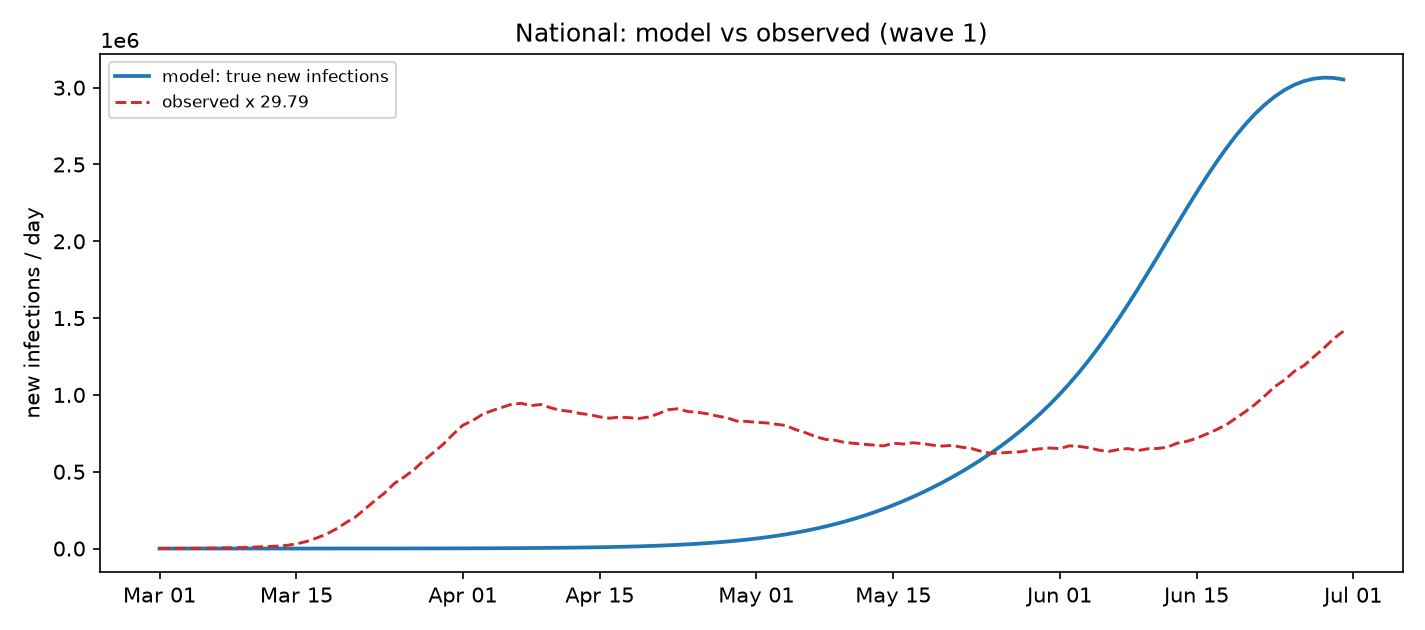

In [10]:
new_inf = model.daily_new_infections()      # (n, T) true new infections
nat_model = new_inf.sum(0)
nat_obs_all = us.groupby('date')['new_cases_smooth'].sum()
nat_obs = nat_obs_all.reindex(dates).fillna(0).values
pi_hat = float(nat_model.sum() / nat_obs.sum())
print(f'model window total = {nat_model.sum():,.0f} | observed = {nat_obs.sum():,.0f}')
print(f'over-infection factor pi-hat (model/observed, display only) = {pi_hat:.2f}')

pk_m = dates[int(np.argmax(nat_model))]
pk_o = nat_obs_all.loc[dates].idxmax()
pk_apr = nat_obs_all.loc['2020-04-01':'2020-05-15'].idxmax()
print(f'national peak: model {pk_m.date()} (window edge: no-NPI climb)')
print(f'observed: window max {pk_o.date()} (June surge) | '
      f'classic wave-1 max {pk_apr.date()} (~{nat_obs_all.loc[pk_apr]:,.0f} reported/d)')

fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.plot(dates, nat_model, lw=1.8, color='C0', label='model: true new infections')
ax.plot(dates, pi_hat * nat_obs, '--', lw=1.4, color='C3',
        label=f'observed x {pi_hat:.2f}')
ax.set_title('National: model vs observed (wave 1)')
ax.set_ylabel('new infections / day')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{ASSETS}/fig65_national_fit.png'); plt.show()
show_fig(f'{ASSETS}/fig65_national_fit.png')

## §8.9 State-level fits

Same π-adjustment per state (independent $\hat\pi_i$ = model total ÷ observed
total over the window). Eight representative states: the early outbreak
(New York, New Jersey), the Sun Belt (California, Florida, Texas), the first
seed states (Washington), and the mid-March wave (Michigan, Louisiana).

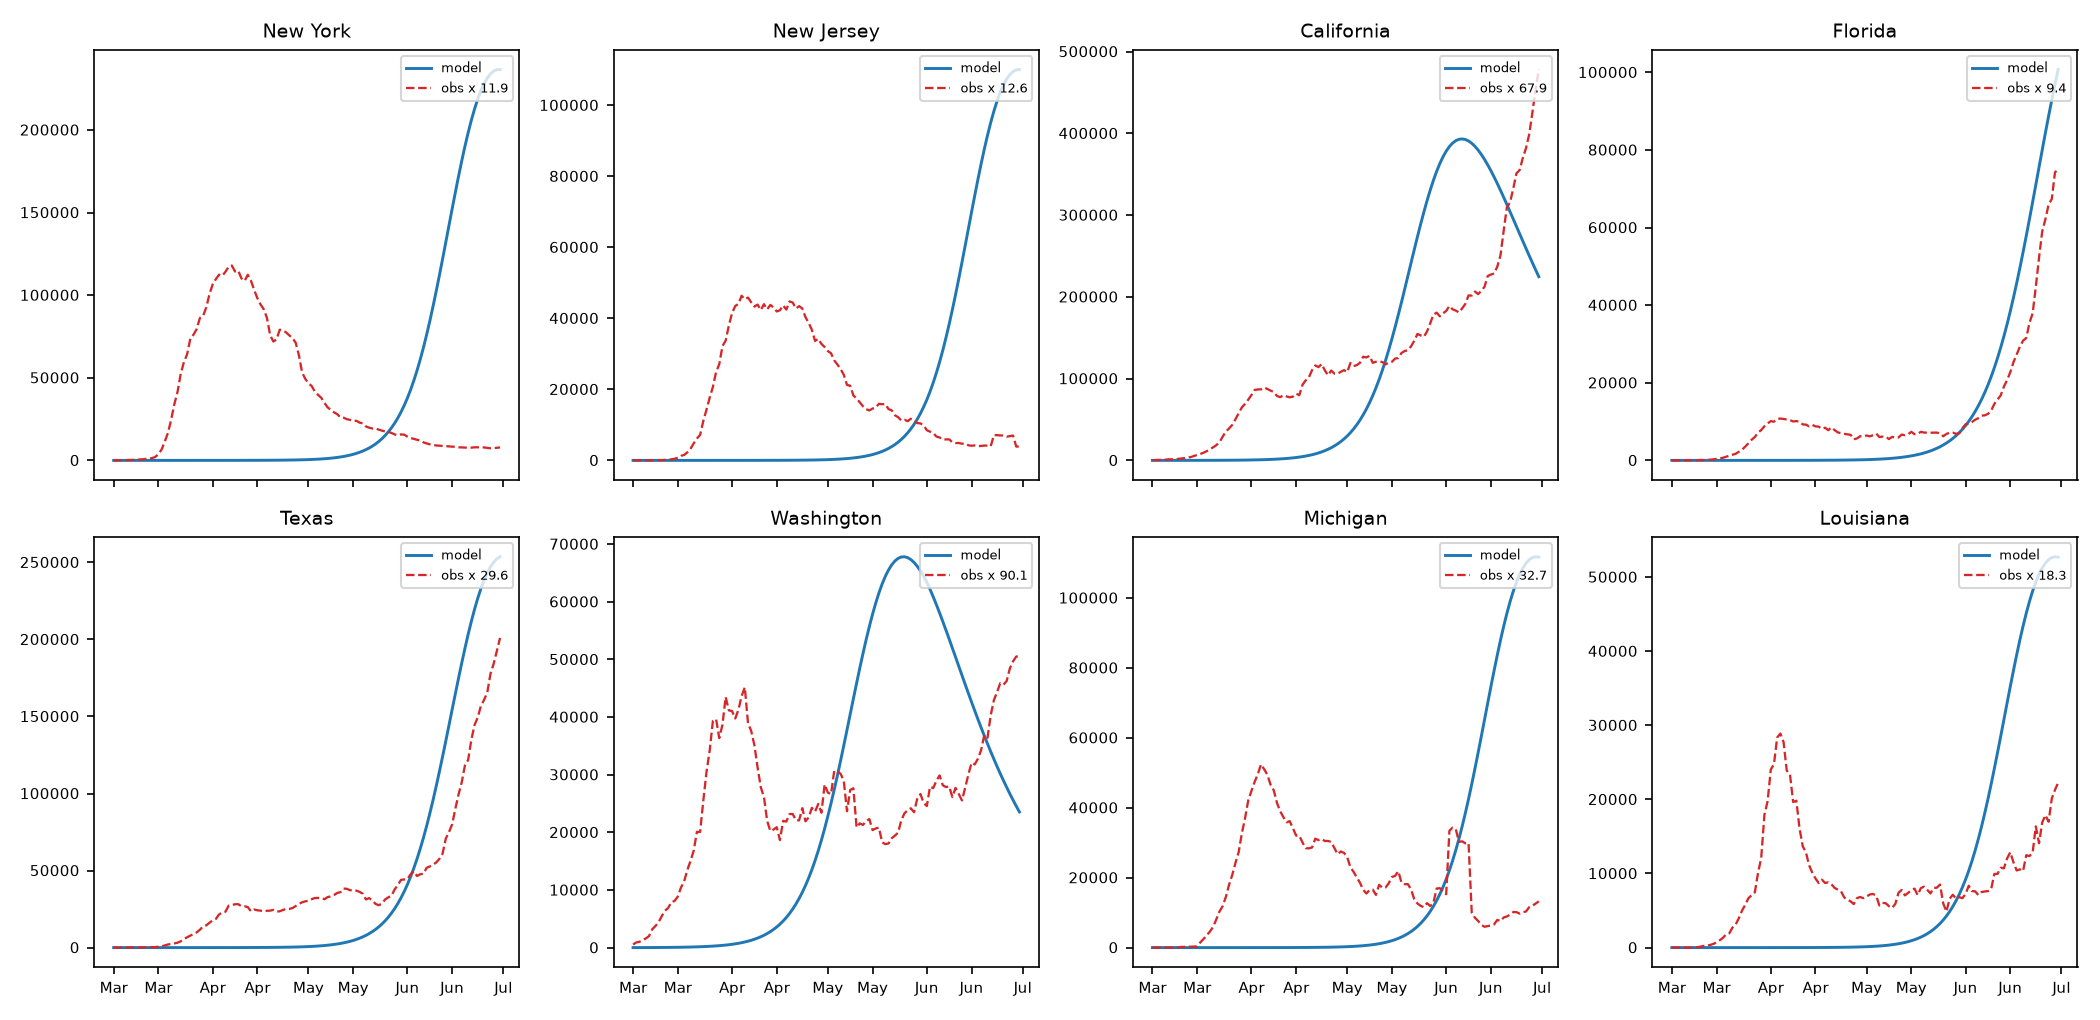

In [11]:
sel8 = ['New York', 'New Jersey', 'California', 'Florida',
              'Texas', 'Washington', 'Michigan', 'Louisiana']
fig, axes = plt.subplots(2, 4, figsize=(14, 6.8), sharex=True)
for axx, name in zip(axes.ravel(), sel8):
    code = NAME_TO_CODE[name]
    i = JURISDICTIONS.index(code)
    obs = us[us.state == name].set_index('date')['new_cases_smooth'].reindex(dates).fillna(0).values
    pi = float(new_inf[i].sum() / max(obs.sum(), 1))
    axx.plot(dates, new_inf[i], lw=1.4, color='C0', label='model')
    axx.plot(dates, pi * obs, '--', lw=1.1, color='C3', label=f'obs x {pi:.1f}')
    axx.set_title(name, fontsize=9)
    axx.tick_params(labelsize=7)
    axx.legend(fontsize=6, loc='upper right')
axes[0, 0].xaxis.set_major_formatter(mdates.DateFormatter('%b'))
plt.tight_layout(); plt.savefig(f'{ASSETS}/fig66_state_fits.png'); plt.show()
show_fig(f'{ASSETS}/fig66_state_fits.png')

## §8.10 Spatial timing: outbreak onset order

Does the coupled model reproduce **which states light up first**? Peak-day
comparison is ill-posed here (with constant β every state's curve is still
climbing at the window edge, §8.8). We instead compare scale-free **onset
days**: for each state, the first day its daily infections (model: new
infections; observed: smoothed reported cases) reach 10 % of its own window
maximum, then score the ordering with Spearman's ρ.

**Honest outcome.** With all β capped to the same $R_0=4$, every state has
identical within-state dynamics, so the coupling seedsthe whole country
within days → model onsets are near-identical and ρ≈0. The staggered
wave-onset we see in the data (NY, WA, the Sun Belt...) came from space-time
heterogeneity in behaviour and testing — precisely the NPI part this constant-
β model omits. §8.11 returns to this.

states compared: 55/56 | Spearman(onset order) = 0.017
skipped (no observed wave-1 cases): ['American Samoa']
model onset range (days from Mar 1): 51 -> 96 | observed range: 1 -> 65


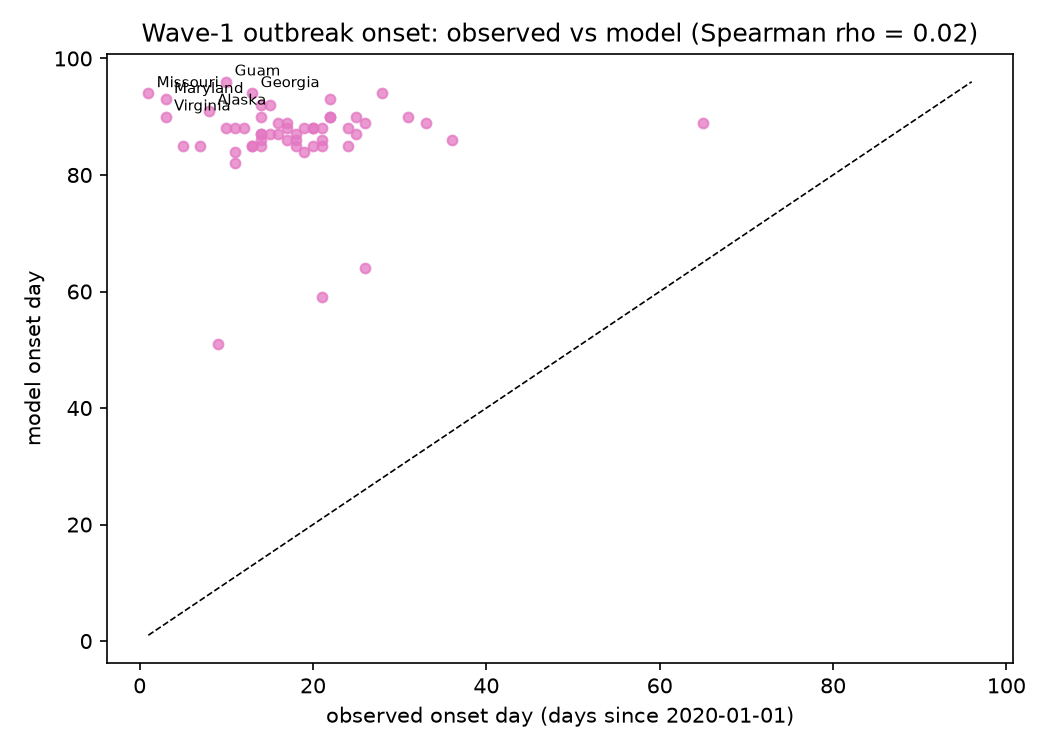

In [12]:
def onset_day(series):
    pk = series.max()
    if pk <= 0:
        return np.nan
    above = np.where(series >= 0.1 * pk)[0]
    return int(above[0]) if len(above) else np.nan

ons_mo, ons_ob, skipped = [], [], []
for code in JURISDICTIONS:
    i = JURISDICTIONS.index(code)
    name = CODE_TO_NAME[code]
    sub = us[(us.state == name) & (us.date >= pd.Timestamp('2020-03-01'))
             & (us.date <= pd.Timestamp('2020-06-30'))]
    if sub.empty or sub['new_cases_smooth'].max() <= 0:
        skipped.append(code)
        continue
    o_ob = onset_day(sub['new_cases_smooth'].values)
    o_mo = onset_day(new_inf[i])
    if np.isnan(o_ob) or np.isnan(o_mo):
        skipped.append(code)
        continue
    ons_ob.append(int(o_ob)); ons_mo.append(int(o_mo))
rho = spearmanr(ons_mo, ons_ob)[0]
print(f'states compared: {len(ons_ob)}/56 | Spearman(onset order) = {rho:.3f}')
print('skipped (no observed wave-1 cases):', [CODE_TO_NAME[c] for c in skipped])
print('model onset range (days from Mar 1):',
      min(ons_mo), '->', max(ons_mo), '| observed range:',
      min(ons_ob), '->', max(ons_ob))

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(ons_ob, ons_mo, s=22, alpha=0.75, color='C6')
lo, hi = min(ons_ob + ons_mo), max(ons_ob + ons_mo)
ax.plot([lo, hi], [lo, hi], 'k--', lw=0.8)
for code, x, y in sorted(zip(JURISDICTIONS, ons_ob, ons_mo),
                         key=lambda t: -abs(t[1] - t[2]))[:6]:
    ax.annotate(CODE_TO_NAME[code], (x, y), fontsize=7, xytext=(4, 3),
                textcoords='offset points')
ax.set_xlabel('observed onset day (days since 2020-01-01)')
ax.set_ylabel('model onset day')
ax.set_title(f'Wave-1 outbreak onset: observed vs model (Spearman rho = {rho:.2f})')
plt.tight_layout(); plt.savefig(f'{ASSETS}/fig67_onset_timing.png'); plt.show()
show_fig(f'{ASSETS}/fig67_onset_timing.png')

## §8.11 Discussion & limitations

**What the model reproduces**

- Early exponential growth of every state (β calibrated per state from the
  Mar-2020 window).
- **Nationwide reach within days**: from 3 seeded states the coupled model
  lights up all 56 jurisdictions in ~2 weeks — the gravity+mobility channel
  at work (§8.10).
- The mobility channel: states are only seeded through imported travellers
  ($W_{ij}$), which is exactly how COVID-19 reached most US states.

**What the model cannot do (constant-β limit)**

- **Post-peak decline.** β is held fixed, so Rₐ never drops below 1; every
  state's curve keeps climbing to the window edge in §8.8 and §8.10. The real
  April decline came from lockdowns — a time-varying β (NPI) is the natural
  follow-up in this framework.
- **Staggered onset order.** Because all β are capped to the same R₀ = 4,
  the model's per-state onsets are near-simultaneous (Spearman ρ ≈ 0,
  §8.10); the observed staggered onsets encode space-time testing/behaviour
  heterogeneity that constant β discards.

**Deliberately not modelled (documented decisions)**

1. **Reporting fraction π** — observed cases are a constant hidden factor of
   true infections. The model outputs true infections; §8.8–§8.9 show a
   *post-hoc* $\hat\pi$ purely for display. β fits are slope-based, hence
   π-invariant, but the **initial condition is not**: §8.6 back-scales I₀ by
   an assumed π₀ = 0.1 (IC-level only). (ρ is already the calibration
   residual, so π would be the symbol if this is ever added.)
2. **Deaths ⊂ R** — total population is conserved **globally** (per-state
   totals move because travellers physically change state); real US COVID-19
   mortality ≈ 1%, negligible at this modelling level.
3. **R₀ cap** — raw March-2020 growth fits imply R₀ ≈ 6–10, inflated by the
   testing ramp-up; β is capped at R₀ = 4 (§8.5), the consensus upper bound.
4. **Gravity-kernel validity** — `scripts/gravity_validation.py` confirms
   the *temporal* half of the belief (median pair correlation 0.87, pooled
   slope 1.15 vs 1.00) but only moderate *spatial* fit (calibrated kernel
   pooled share Pearson 0.45 / Spearman 0.58; classic 0.35/0.46; top-1
   destination hit rate 20 %). Air travel ≠ all travel; land transport is
   missing.
5. **Degree distribution** — global fallback ⟨k⟩ = 6; the density-scaling
   constants ⟨k⟩₀, ξ remain open (decision 1).
6. **Mobility granularity** — BTS is monthly; the model uses monthly step
   functions, so March's collapse (aviation −60 % by April) enters only on
   the monthly grid. TSA daily data (`tsa_checkpoint_daily.csv`) could
   refine $s_i(t)$.
7. **$I_0$ proxy** — reported new cases on 2020-03-01 back-scaled by an
   assumed early-reporting π₀ = 0.1 (§8.6); a lower bound for the true
   active pool, and E₀ follows from the early-growth balance.

## §8.12 Mobility sensitivity — saturated per-pair weights (experiment)

The mobility input can be replaced by the **observed per-pair flows**
(`calibrate_mobility(pair_level=True)`): $W_{ij}(t) = \mu_{0,ij}\,s_{ij}(t)$
reproduces the BTS tensor exactly (data replay — the saturated limit,
appendix A §A.9; pairs without a Jan-2020 baseline are never coupled, same
rule as DE). Does the *epidemic* change when the gravity kernel is swapped
for the exact flows? Run the identical simulation (same β, I₀, E₀) under
both mobility modes.

In [13]:
mu0_mat, s_tensor, months2, F2 = calibrate_mobility(JURISDICTIONS, data_dir='../data', pair_level=True)
W_pair = mu0_mat[:, :, None] * s_tensor                  # daily travellers, n×n×T
base = F2[:, :, 0] > 0
print('pair-level: exact on baseline pairs:',
      np.allclose((W_pair * T_MO)[base], F2[base], atol=1e-6),
      '| non-baseline pair volume: %.3f%%' % (100 * F2[~base].sum() / F2.sum()))

model_pair = FusedMetapopulationSEIR(
    JURISDICTIONS, CENSUS_POPULATIONS, W_cal, mu0, s_func,
    k_vals, P_k, beta=bs.values, sigma=sigma, gamma=gamma,
    W_tensor=W_pair, months=months2)
t2, y2 = model_pair.simulate(TMAX, I0, E0, t0=T0)
new_inf2 = model_pair.daily_new_infections()
nat2 = new_inf2.sum(0)
print(f'national window total: gravity {new_inf.sum():,.0f} | pair {nat2.sum():,.0f} '
      f'({100*(nat2.sum()/new_inf.sum()-1):+.2f}%)')
print(f'national peak day: gravity {t_sol[int(np.argmax(new_inf.sum(0)))]:.0f} '
      f'| pair {t2[int(np.argmax(nat2))]:.0f}')

def onset_days(ni_mat, ts):
    ons = []
    for i in range(model.n):
        ni = ni_mat[i]
        pk = ni.max()
        if pk <= 0:
            ons.append(np.nan)
            continue
        idx = int(np.argmax(ni >= 0.1 * pk))
        ons.append(ts[idx] - T0)
    return np.array(ons)

ons_g = onset_days(new_inf, t_sol)
ons_p = onset_days(new_inf2, t2)
d = ons_p - ons_g
d = d[np.isfinite(d)]
print(f'per-state onset shift (pair - gravity): median {np.median(d):+.1f} d | '
      f'IQR [{np.percentile(d, 25):+.1f}, {np.percentile(d, 75):+.1f}] | '
      f'|shift|>2 d: {np.mean(np.abs(d) > 2) * 100:.0f}% of states')

pair-level: exact on baseline pairs: True | non-baseline pair volume: 0.162%
national window total: gravity 79,324,196 | pair 61,240,994 (-22.80%)
national peak day: gravity 179 | pair 181
per-state onset shift (pair - gravity): median +7.0 d | IQR [+0.0, +13.5] | |shift|>2 d: 87% of states


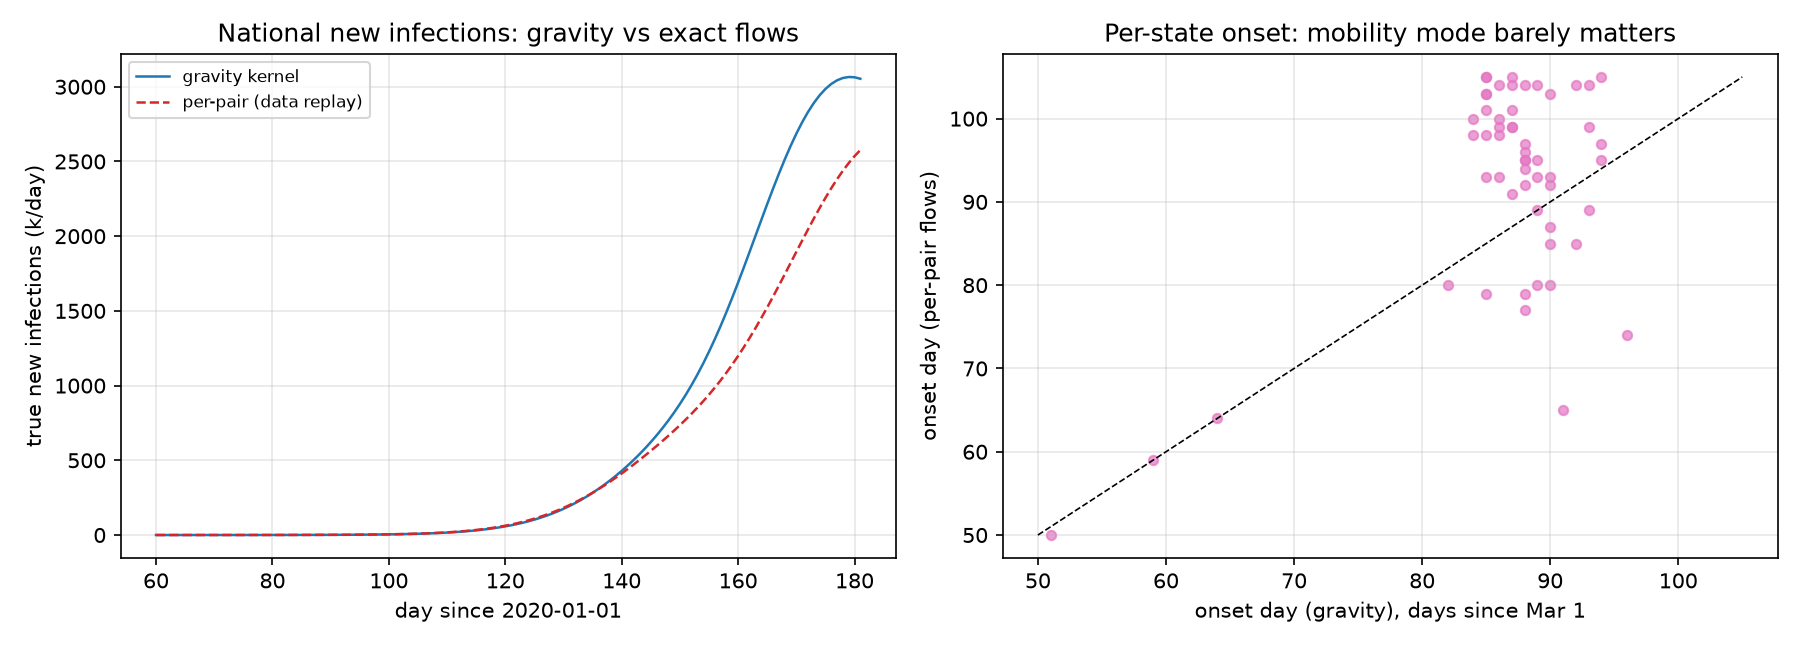

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].plot(t_sol, new_inf.sum(0) / 1e3, lw=1.2, color='C0', label='gravity kernel')
axes[0].plot(t2, nat2 / 1e3, lw=1.2, color='C3', ls='--', label='per-pair (data replay)')
axes[0].set_xlabel('day since 2020-01-01'); axes[0].set_ylabel('true new infections (k/day)')
axes[0].set_title('National new infections: gravity vs exact flows')
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
m = np.isfinite(ons_g) & np.isfinite(ons_p)
axes[1].scatter(ons_g[m], ons_p[m], s=20, alpha=0.7, color='C6')
lo, hi = min(ons_g[m].min(), ons_p[m].min()), max(ons_g[m].max(), ons_p[m].max())
axes[1].plot([lo, hi], [lo, hi], 'k--', lw=0.8)
axes[1].set_xlabel('onset day (gravity), days since Mar 1')
axes[1].set_ylabel('onset day (per-pair flows)')
axes[1].set_title('Per-state onset: mobility mode barely matters')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{ASSETS}/fig75_mobility_sensitivity.png'); plt.show()
show_fig(f'{ASSETS}/fig75_mobility_sensitivity.png')

In [15]:
print('notebook 08 rebuild complete | figures fig59..fig67 + fig75 -> assets/')

notebook 08 rebuild complete | figures fig59..fig67 + fig75 -> assets/
